In [1]:
#1
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)
print("Libraries imported successfully!")

PyTorch version: 2.11.0+cpu
Device: cpu
Libraries imported successfully!
PyTorch version: 2.11.0+cpu
Device: cpu
Libraries imported successfully!


In [2]:
#2
df = pd.read_csv("secom_telemetry_modified.csv")

In [3]:
#3
df.shape

(1567, 592)

In [4]:
#4
df.head()

,sensor_0,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,...,sensor_582,sensor_583,sensor_584,sensor_585,sensor_586,sensor_587,sensor_588,sensor_589,label,timestamp
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN,-1,2008-07-19 11:55:00
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045,-1,2008-07-19 12:32:00
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602,1,2008-07-19 13:17:00
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432,-1,2008-07-19 14:43:00
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432,-1,2008-07-19 15:22:00


In [5]:
#5
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1567 entries, 0 to 1566
Columns: 592 entries, sensor_0 to timestamp
dtypes: float64(590), int64(1), object(1)
memory usage: 7.1+ MB


In [6]:
#6
df.columns.tolist()

['sensor_0',
 'sensor_1',
 'sensor_2',
 'sensor_3',
 'sensor_4',
 'sensor_5',
 'sensor_6',
 'sensor_7',
 'sensor_8',
 'sensor_9',
 'sensor_10',
 'sensor_11',
 'sensor_12',
 'sensor_13',
 'sensor_14',
 'sensor_15',
 'sensor_16',
 'sensor_17',
 'sensor_18',
 'sensor_19',
 'sensor_20',
 'sensor_21',
 'sensor_22',
 'sensor_23',
 'sensor_24',
 'sensor_25',
 'sensor_26',
 'sensor_27',
 'sensor_28',
 'sensor_29',
 'sensor_30',
 'sensor_31',
 'sensor_32',
 'sensor_33',
 'sensor_34',
 'sensor_35',
 'sensor_36',
 'sensor_37',
 'sensor_38',
 'sensor_39',
 'sensor_40',
 'sensor_41',
 'sensor_42',
 'sensor_43',
 'sensor_44',
 'sensor_45',
 'sensor_46',
 'sensor_47',
 'sensor_48',
 'sensor_49',
 'sensor_50',
 'sensor_51',
 'sensor_52',
 'sensor_53',
 'sensor_54',
 'sensor_55',
 'sensor_56',
 'sensor_57',
 'sensor_58',
 'sensor_59',
 'sensor_60',
 'sensor_61',
 'sensor_62',
 'sensor_63',
 'sensor_64',
 'sensor_65',
 'sensor_66',
 'sensor_67',
 'sensor_68',
 'sensor_69',
 'sensor_70',
 'sensor_71',
 '

In [7]:
#7
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

sensor_cols = [col for col in df.columns if col.startswith("sensor_")]

df.shape

(1567, 592)

In [8]:
#8
df["label"].value_counts(dropna=False)

,count
label,
-1,1463
1,104


In [9]:
#9
df["label"].value_counts(normalize=True, dropna=False) * 100


,proportion
label,
-1,93.363114
1,6.636886


In [10]:
#10
audit = pd.Series({
    "Total wafers": len(df),
    "Sensor features": len(sensor_cols),
    "Missing labels": df["label"].isna().sum(),
    "Missing timestamps": df["timestamp"].isna().sum(),
    "Duplicate timestamps": df["timestamp"].duplicated().sum(),
    "Missing sensor values": df[sensor_cols].isna().sum().sum(),
    "Start timestamp": df["timestamp"].min(),
    "End timestamp": df["timestamp"].max()
})

audit

,0
Total wafers,1567
Sensor features,590
Missing labels,0
Missing timestamps,0
Duplicate timestamps,33
Missing sensor values,41948
Start timestamp,2008-07-19 11:55:00
End timestamp,2008-10-17 06:07:00


In [11]:
#11
legacy_mask = df["sensor_0"].eq(0.0)

pd.DataFrame({
    "Metric": [
        "Legacy wafers",
        "Non-legacy wafers",
        "Legacy firmware code 100",
        "Legacy firmware code 200",
        "Legacy firmware code 300"
    ],
    "Count": [
        legacy_mask.sum(),
        (~legacy_mask).sum(),
        (legacy_mask & df["sensor_1"].eq(100.0)).sum(),
        (legacy_mask & df["sensor_1"].eq(200.0)).sum(),
        (legacy_mask & df["sensor_1"].eq(300.0)).sum()
    ]
})

,Metric,Count
0,Legacy wafers,146
1,Non-legacy wafers,1421
2,Legacy firmware code 100,61
3,Legacy firmware code 200,35
4,Legacy firmware code 300,50


In [12]:
#12

df = df.sort_values("timestamp", kind="stable").reset_index(drop=True)

assert df["timestamp"].notna().all()
assert df["label"].notna().all()
assert set(df["label"].unique()) == {-1, 1}

X_raw = df[sensor_cols].copy()
y = (df["label"] == 1).astype(np.float32)

legacy_mask = X_raw["sensor_0"].eq(0.0)

X_raw.shape, y.shape, legacy_mask.sum()

((1567, 590), (1567,), np.int64(146))

In [13]:
#13

n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train_raw = X_raw.iloc[:train_end].copy()
X_val_raw = X_raw.iloc[train_end:val_end].copy()
X_test_raw = X_raw.iloc[val_end:].copy()

y_train = y.iloc[:train_end].copy()
y_val = y.iloc[train_end:val_end].copy()
y_test = y.iloc[val_end:].copy()

pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Rows": [len(y_train), len(y_val), len(y_test)],
    "Defects": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "Defect prevalence (%)": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100
    ],
    "Start": [
        df["timestamp"].iloc[0],
        df["timestamp"].iloc[train_end],
        df["timestamp"].iloc[val_end]
    ],
    "End": [
        df["timestamp"].iloc[train_end - 1],
        df["timestamp"].iloc[val_end - 1],
        df["timestamp"].iloc[-1]
    ]
})

,Split,Rows,Defects,Defect prevalence (%),Start,End
0,Train,1096,78,7.116789,2008-07-19 11:55:00,2008-09-26 02:26:00
1,Validation,235,17,7.234043,2008-09-26 03:12:00,2008-10-05 18:59:00
2,Test,236,9,3.813559,2008-10-05 19:45:00,2008-10-17 06:07:00


In [14]:
#14

def separate_legacy_features(X):
    X = X.copy()

    legacy = X["sensor_0"].eq(0.0)

    firmware = pd.Series("non_legacy", index=X.index, dtype="object")
    firmware.loc[legacy & X["sensor_1"].eq(100.0)] = "firmware_100"
    firmware.loc[legacy & X["sensor_1"].eq(200.0)] = "firmware_200"
    firmware.loc[legacy & X["sensor_1"].eq(300.0)] = "firmware_300"
    firmware.loc[legacy & ~X["sensor_1"].isin([100.0, 200.0, 300.0])] = "unknown"

    X["legacy_indicator"] = legacy.astype(np.float32)
    X["firmware_category"] = firmware

    X.loc[legacy, "sensor_0"] = np.nan
    X.loc[legacy, "sensor_1"] = np.nan

    return X


X_train = separate_legacy_features(X_train_raw)
X_val = separate_legacy_features(X_val_raw)
X_test = separate_legacy_features(X_test_raw)

In [15]:
#15
X_train["firmware_category"].value_counts()

,count
firmware_category,
non_legacy,998
firmware_100,40
firmware_300,33
firmware_200,25


In [16]:
#16
continuous_cols = [
    col for col in X_train.columns
    if col not in ["firmware_category"]
]

categorical_cols = ["firmware_category"]

In [17]:
#17
imputer = SimpleImputer(strategy="median")
scaler = RobustScaler()

X_train_cont = imputer.fit_transform(X_train[continuous_cols])
X_val_cont = imputer.transform(X_val[continuous_cols])
X_test_cont = imputer.transform(X_test[continuous_cols])

X_train_cont = scaler.fit_transform(X_train_cont)
X_val_cont = scaler.transform(X_val_cont)
X_test_cont = scaler.transform(X_test_cont)

In [18]:
#18
firmware_categories = [
    "non_legacy",
    "firmware_100",
    "firmware_200",
    "firmware_300",
    "unknown"
]

def encode_firmware(X):
    return np.column_stack([
        X["firmware_category"].eq(category).to_numpy(dtype=np.float32)
        for category in firmware_categories
    ])

X_train_cat = encode_firmware(X_train)
X_val_cat = encode_firmware(X_val)
X_test_cat = encode_firmware(X_test)

X_train_processed = np.concatenate([X_train_cont, X_train_cat], axis=1)
X_val_processed = np.concatenate([X_val_cont, X_val_cat], axis=1)
X_test_processed = np.concatenate([X_test_cont, X_test_cat], axis=1)

In [19]:
#19
X_train_processed.shape, X_val_processed.shape, X_test_processed.shape

((1096, 596), (235, 596), (236, 596))

In [20]:
#20
X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_processed, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_processed, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

In [21]:
#21
class Autoencoder(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, 16)
        )

        self.decoder = nn.Sequential(
            nn.Linear(16, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, input_dim)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


model = Autoencoder(X_train_tensor.shape[1]).to(DEVICE)

In [22]:
#22
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [23]:
#23
EPOCHS = 50

train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for (batch,) in train_loader:
        batch = batch.to(DEVICE)

        optimizer.zero_grad()

        reconstruction = model(batch)
        loss = criterion(reconstruction, batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * batch.size(0)

    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for start in range(0, len(X_val_tensor), 64):
            batch = X_val_tensor[start:start + 64].to(DEVICE)

            reconstruction = model(batch)
            loss = criterion(reconstruction, batch)

            val_loss += loss.item() * batch.size(0)

    val_loss /= len(X_val_tensor)
    val_losses.append(val_loss)

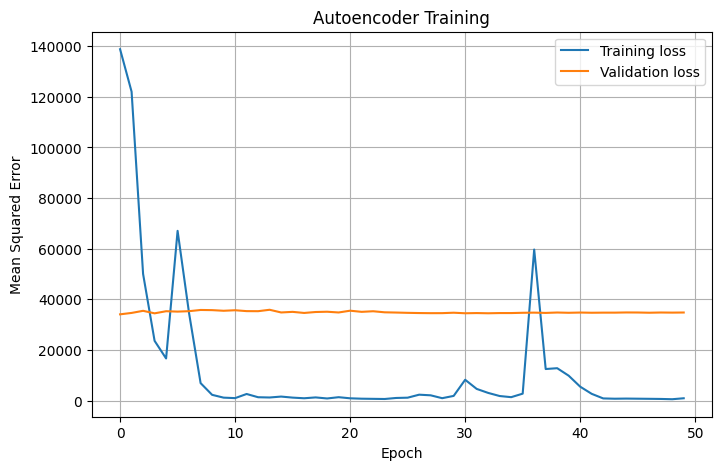

In [24]:
#24
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Autoencoder Training")
plt.legend()
plt.grid(True)
plt.show()

In [25]:
#25
pd.DataFrame({
    "Metric": ["Training loss", "Validation loss"],
    "Value": [train_losses[-1], val_losses[-1]]
})

,Metric,Value
0,Training loss,950.364820
1,Validation loss,34809.671813


training loss eventually drops to 950, but the validation loss stays around 34,810.
this is like genralization problem The spikes in training loss also indicate unstable training

In [26]:
#26
model = Autoencoder(X_train_tensor.shape[1]).to(DEVICE)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 30
train_losses = []
val_losses = []

In [27]:
#27
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for (batch,) in train_loader:
        batch = batch.to(DEVICE)

        optimizer.zero_grad()

        reconstruction = model(batch)
        loss = criterion(reconstruction, batch)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        train_loss += loss.item() * batch.size(0)

    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for start in range(0, len(X_val_tensor), 64):
            batch = X_val_tensor[start:start + 64].to(DEVICE)

            reconstruction = model(batch)
            loss = criterion(reconstruction, batch)

            val_loss += loss.item() * batch.size(0)

    val_loss /= len(X_val_tensor)
    val_losses.append(val_loss)

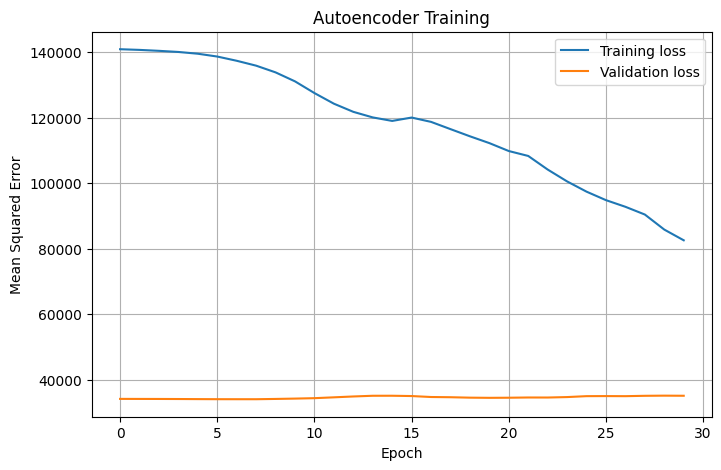

In [28]:
#28
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Autoencoder Training")
plt.legend()
plt.grid(True)
plt.show()

In [29]:
#29
pd.DataFrame({
    "Feature": np.arange(X_train_processed.shape[1]),
    "Train mean": X_train_processed.mean(axis=0),
    "Train std": X_train_processed.std(axis=0),
    "Train max abs": np.abs(X_train_processed).max(axis=0),
    "Validation max abs": np.abs(X_val_processed).max(axis=0)
}).sort_values("Train max abs", ascending=False).head(15)

,Feature,Train mean,Train std,Train max abs,Validation max abs
340,340,468.359929,7737.257177,130669.119171,1.357513
204,204,263.362122,4346.580616,72081.661139,1.392934
67,67,131.133168,2223.653703,44219.007601,3.499544
287,287,2.781785,76.568756,2536.022140,14.274365
152,152,2.409474,65.673512,2175.165509,12.688287
523,523,6.184231,78.515081,1991.727842,1155.061773
251,251,5.404653,65.650229,1650.000000,982.666667
389,389,4.939781,62.116737,1562.000000,930.500000
158,158,3.038032,119.747113,1465.099600,806.100600
521,521,9.274770,91.813722,1000.000000,1000.000000


In [30]:
#30
pd.Series({
    "Train NaN": np.isnan(X_train_processed).sum(),
    "Validation NaN": np.isnan(X_val_processed).sum(),
    "Test NaN": np.isnan(X_test_processed).sum(),
    "Train infinite": np.isinf(X_train_processed).sum(),
    "Validation infinite": np.isinf(X_val_processed).sum(),
    "Test infinite": np.isinf(X_test_processed).sum()
})

,0
Train NaN,0
Validation NaN,0
Test NaN,0
Train infinite,0
Validation infinite,0
Test infinite,0


In [31]:
#31
pd.Series({
    "Train maximum absolute value": np.abs(X_train_processed).max(),
    "Validation maximum absolute value": np.abs(X_val_processed).max(),
    "Test maximum absolute value": np.abs(X_test_processed).max()
})

,0
Train maximum absolute value,130669.119171
Validation maximum absolute value,35264.735979
Test maximum absolute value,78094.720207


In [32]:
#32
feature_names = continuous_cols + [
    f"firmware_{category}" for category in firmware_categories
]

extreme_features = pd.DataFrame({
    "Feature": feature_names,
    "Train max abs": np.abs(X_train_processed).max(axis=0),
    "Validation max abs": np.abs(X_val_processed).max(axis=0),
    "Test max abs": np.abs(X_test_processed).max(axis=0)
})

extreme_features.sort_values(
    "Train max abs", ascending=False
).head(15)

,Feature,Train max abs,Validation max abs,Test max abs
340,sensor_340,130669.119171,1.357513,78094.720207
204,sensor_204,72081.661139,1.392934,72085.626532
67,sensor_67,44219.007601,3.499544,5526.947400
287,sensor_287,2536.022140,14.274365,4.661168
152,sensor_152,2175.165509,12.688287,4.389759
523,sensor_523,1991.727842,1155.061773,75.190689
251,sensor_251,1650.000000,982.666667,67.333333
389,sensor_389,1562.000000,930.500000,63.000000
158,sensor_158,1465.099600,806.100600,826.900400
521,sensor_521,1000.000000,1000.000000,1000.000000


In [33]:
#33
pd.DataFrame({
    "Feature": feature_names,
    "Train std": X_train_processed.std(axis=0),
    "Validation std": X_val_processed.std(axis=0),
    "Test std": X_test_processed.std(axis=0)
}).sort_values("Train std").head(20)

,Feature,Train std,Validation std,Test std
595,firmware_unknown,0.0,0.0,0.0
380,sensor_380,0.0,0.0,0.0
379,sensor_379,0.0,0.0,0.0
378,sensor_378,0.0,0.0,0.0
5,sensor_5,0.0,0.0,0.0
534,sensor_534,0.0,0.0,0.0
535,sensor_535,0.0,0.0,0.0
381,sensor_381,0.0,0.0,0.0
284,sensor_284,0.0,0.0,0.0
276,sensor_276,0.0,0.0,0.0


In [34]:
#34
continuous_cols = [
    col for col in X_train.columns
    if col != "firmware_category"
]

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train[continuous_cols])
X_val_imputed = imputer.transform(X_val[continuous_cols])
X_test_imputed = imputer.transform(X_test[continuous_cols])

train_std = X_train_imputed.std(axis=0)
keep_mask = train_std > 0

continuous_cols_kept = np.array(continuous_cols)[keep_mask].tolist()

X_train_imputed = X_train_imputed[:, keep_mask]
X_val_imputed = X_val_imputed[:, keep_mask]
X_test_imputed = X_test_imputed[:, keep_mask]

In [35]:
#35
scaler = RobustScaler()

X_train_cont = scaler.fit_transform(X_train_imputed)
X_val_cont = scaler.transform(X_val_imputed)
X_test_cont = scaler.transform(X_test_imputed)

X_train_cont = np.clip(X_train_cont, -10, 10)
X_val_cont = np.clip(X_val_cont, -10, 10)
X_test_cont = np.clip(X_test_cont, -10, 10)

In [36]:
#36
X_train_cat = encode_firmware(X_train)
X_val_cat = encode_firmware(X_val)
X_test_cat = encode_firmware(X_test)

X_train_processed = np.concatenate(
    [X_train_cont, X_train_cat], axis=1
)
X_val_processed = np.concatenate(
    [X_val_cont, X_val_cat], axis=1
)
X_test_processed = np.concatenate(
    [X_test_cont, X_test_cat], axis=1
)

In [37]:
#37
pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Rows": [
        X_train_processed.shape[0],
        X_val_processed.shape[0],
        X_test_processed.shape[0]
    ],
    "Features": [
        X_train_processed.shape[1],
        X_val_processed.shape[1],
        X_test_processed.shape[1]
    ],
    "Maximum absolute value": [
        np.abs(X_train_processed).max(),
        np.abs(X_val_processed).max(),
        np.abs(X_test_processed).max()
    ]
})

,Split,Rows,Features,Maximum absolute value
0,Train,1096,474,10.0
1,Validation,235,474,10.0
2,Test,236,474,10.0


In [39]:
#38
X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_processed, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_processed, dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

In [ ]:
#39

In [40]:
#40
model = Autoencoder(X_train_tensor.shape[1]).to(DEVICE)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 50
train_losses = []
val_losses = []

In [41]:
#41
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for (batch,) in train_loader:
        batch = batch.to(DEVICE)

        optimizer.zero_grad()

        reconstruction = model(batch)
        loss = criterion(reconstruction, batch)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        train_loss += loss.item() * batch.size(0)

    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for start in range(0, len(X_val_tensor), 64):
            batch = X_val_tensor[start:start + 64].to(DEVICE)
            reconstruction = model(batch)
            loss = criterion(reconstruction, batch)
            val_loss += loss.item() * batch.size(0)

    val_loss /= len(X_val_tensor)
    val_losses.append(val_loss)

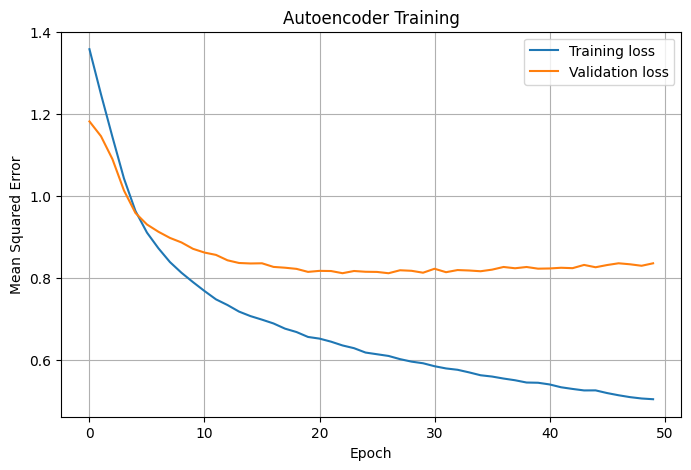

In [42]:
#42
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Autoencoder Training")
plt.legend()
plt.grid(True)
plt.show()

In [43]:
#43
pd.DataFrame({
    "Metric": ["Training loss", "Validation loss"],
    "Value": [train_losses[-1], val_losses[-1]]
})

,Metric,Value
0,Training loss,0.503121
1,Validation loss,0.835077


In [44]:
#44
def reconstruction_errors(model, X, batch_size=64):
    model.eval()
    errors = []

    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            batch = X[start:start + batch_size].to(DEVICE)
            reconstruction = model(batch)

            batch_errors = ((reconstruction - batch) ** 2).mean(dim=1)
            errors.extend(batch_errors.cpu().numpy())

    return np.asarray(errors)


train_scores = reconstruction_errors(model, X_train_tensor)
val_scores = reconstruction_errors(model, X_val_tensor)
test_scores = reconstruction_errors(model, X_test_tensor)

In [45]:
#45
pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Mean anomaly score": [
        train_scores.mean(),
        val_scores.mean(),
        test_scores.mean()
    ],
    "Median anomaly score": [
        np.median(train_scores),
        np.median(val_scores),
        np.median(test_scores)
    ],
    "Maximum anomaly score": [
        train_scores.max(),
        val_scores.max(),
        test_scores.max()
    ]
})

,Split,Mean anomaly score,Median anomaly score,Maximum anomaly score
0,Train,0.491988,0.466863,1.261310
1,Validation,0.835077,0.759892,3.067284
2,Test,0.987480,0.868927,3.239563


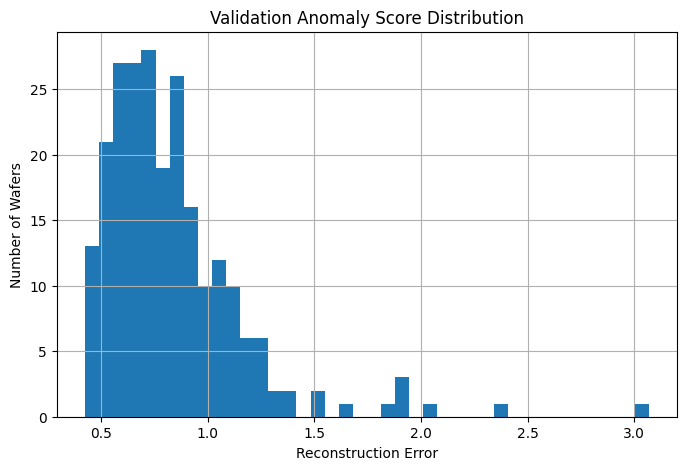

In [46]:
#46
plt.figure(figsize=(8, 5))
plt.hist(val_scores, bins=40)
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Wafers")
plt.title("Validation Anomaly Score Distribution")
plt.grid(True)
plt.show()

In [47]:
#47
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_scores
)

f1_values = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f1_values)
threshold = thresholds[best_idx]

pd.DataFrame({
    "Metric": [
        "Selected threshold",
        "Validation precision",
        "Validation recall",
        "Validation F1"
    ],
    "Value": [
        threshold,
        precision[best_idx],
        recall[best_idx],
        f1_values[best_idx]
    ]
})

,Metric,Value
0,Selected threshold,1.116271
1,Validation precision,0.172414
2,Validation recall,0.294118
3,Validation F1,0.217391


In [48]:
#48
test_predictions = (test_scores >= threshold).astype(int)

test_metrics = {
    "Test wafers": len(y_test),
    "Actual defects": int(y_test.sum()),
    "Defect prevalence (%)": y_test.mean() * 100,
    "ROC-AUC": roc_auc_score(y_test, test_scores),
    "Average precision": average_precision_score(y_test, test_scores),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1": f1_score(y_test, test_predictions, zero_division=0)
}

pd.DataFrame(test_metrics.items(), columns=["Metric", "Value"])

,Metric,Value
0,Test wafers,236.000000
1,Actual defects,9.000000
2,Defect prevalence (%),3.813559
3,ROC-AUC,0.566814
4,Average precision,0.061942
5,Precision,0.070175
6,Recall,0.444444
7,F1,0.121212


In [50]:
#49
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])

pd.DataFrame(
    cm,
    index=["Actual Normal", "Actual Defect"],
    columns=["Predicted Normal", "Predicted Defect"]
)

,Predicted Normal,Predicted Defect
Actual Normal,174,53
Actual Defect,5,4


In [51]:
#50
results = {
    "model": "Autoencoder",
    "threshold": float(threshold),
    "train_wafers": len(y_train),
    "validation_wafers": len(y_val),
    "test_wafers": len(y_test),
    "train_defect_prevalence": float(y_train.mean()),
    "validation_defect_prevalence": float(y_val.mean()),
    "test_defect_prevalence": float(y_test.mean()),
    "features_after_preprocessing": int(X_train_processed.shape[1]),
    "roc_auc": float(roc_auc_score(y_test, test_scores)),
    "average_precision": float(average_precision_score(y_test, test_scores)),
    "precision": float(precision_score(y_test, test_predictions, zero_division=0)),
    "recall": float(recall_score(y_test, test_predictions, zero_division=0)),
    "f1": float(f1_score(y_test, test_predictions, zero_division=0)),
    "true_negatives": int(cm[0, 0]),
    "false_positives": int(cm[0, 1]),
    "false_negatives": int(cm[1, 0]),
    "true_positives": int(cm[1, 1])
}

pd.Series(results, name="Value")

,Value
model,Autoencoder
threshold,1.116271
train_wafers,1096
validation_wafers,235
test_wafers,236
train_defect_prevalence,0.071168
validation_defect_prevalence,0.07234
test_defect_prevalence,0.038136
features_after_preprocessing,474
roc_auc,0.566814


In [ ]:
#51